In [2]:
import pandas as pd
import numpy as np
import io

In [7]:
df = pd.read_csv("retail_x_clientes.csv")
df.head()

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0


In [8]:
# Diagnóstico estructural
print("--- DIMENSIONES ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")

print("--- INSPECCIÓN DE TIPOS DE DATOS ---")
df.info()

print("\n--- MUESTRA REGISTROS CRUDOS ---")
print(df.head(3))

--- DIMENSIONES ---
Filas: 10000, Columnas: 8

--- INSPECCIÓN DE TIPOS DE DATOS ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          10000 non-null  int64  
 1   edad                 10000 non-null  int64  
 2   ingresos             7000 non-null   float64
 3   ciudad               10000 non-null  str    
 4   fecha_ultima_compra  10000 non-null  str    
 5   num_compras          10000 non-null  int64  
 6   deuda                10000 non-null  float64
 7   churn                8999 non-null   float64
dtypes: float64(3), int64(3), str(2)
memory usage: 625.1 KB

--- MUESTRA REGISTROS CRUDOS ---
   customer_id  edad  ingresos            ciudad fecha_ultima_compra  \
0         1860    50  23962.22  Ciudad de México          2023-08-30   
1         4772    49       NaN            puebla          2023-06-05   
2         

In [9]:
# Mascara de detección de registros desplazados
mask_desplazados = ~df['fecha_ultima_compra'].str.contains(r'\d{2}/\d{2}/\d{4}', na=False)

print(f"Registros con columnas desplazadas detectados: {mask_desplazados.sum()}")
print("Muestra de filas desplazadas:")
print(df[mask_desplazados][['ciudad', 'fecha_ultima_compra', 'num_compras', 'deuda']])

Registros con columnas desplazadas detectados: 10000
Muestra de filas desplazadas:
                ciudad fecha_ultima_compra  num_compras    deuda
0     Ciudad de México          2023-08-30            4  5365.92
1               puebla          2023-06-05            5  4692.15
2                 CDMX          2022-11-29            9  4617.36
3               Puebla          2021-10-09            5  2101.78
4     Ciudad de México          2023-09-02            3 -1798.42
...                ...                 ...          ...      ...
9995              CDMX          2021-07-31            6  2035.49
9996              CDMX          2022-01-17            4  4674.32
9997       México D.F.          2021-02-10            1  6148.24
9998            Puebla          2021-10-30            2  3710.74
9999            Puebla          2024-02-24            6  2112.72

[10000 rows x 4 columns]


In [6]:
# realineación de registros desplazados
for idx in df[mask_desplazados].index:
    # 1. Extraer la fecha (ultimos 10 caracteres) y la ciudad limpia de la columna 'ciudad'
    cadena_compuesta = str(df.loc[idx, 'ciudad'])
    fecha_extraida = cadena_compuesta[-10:]
    ciudad_limpia = cadena_compuesta[:-10].strip()
    
    # 2. Re-alinear los campos hacia la derecha
    df.loc[idx, 'deuda'] = df.loc[idx, 'num_compras']
    df.loc[idx, 'num_compras'] = df.loc[idx, 'fecha_ultima_compra']
    df.loc[idx, 'fecha_ultima_compra'] = fecha_extraida
    df.loc[idx, 'ciudad'] = ciudad_limpia

# Cast correcto de tipos de datos tras la re-alineación
df['num_compras'] = df['num_compras'].astype(float)
df['deuda'] = df['deuda'].astype(float)

print("\n--- VERIFICACIÓN TRAS REALINEACIÓN ---")
print(df.loc[mask_desplazados, ['ciudad', 'fecha_ultima_compra', 'num_compras', 'deuda']])


TypeError: Invalid value '2023-08-30' for dtype 'int64'

In [24]:
# 1. Conteo y Porcentaje de Valores Faltantes
nulos_diag = pd.DataFrame({
    'Nulos_Absolutos': df.isna().sum(),
    'Porcentaje_%': (df.isna().mean() * 100).round(2)
})
print("--- DIAGNÓSTICO DE VALORES FALTANTES ---")
print(nulos_diag)

# 2. Evaluación del Coeficiente de Asimetría (Skewness) para 'ingresos'
skew_ingresos = df['ingresos'].skew()
print(f"\nCoeficiente de Asimetría (Skewness) de 'ingresos': {skew_ingresos:.4f}")
skew_deuda = df['deuda'].skew()
print(f"Coeficiente de Asimetría (Skewness) de 'deuda': {skew_deuda:.4f}")


--- DIAGNÓSTICO DE VALORES FALTANTES ---
                     Nulos_Absolutos  Porcentaje_%
customer_id                        0          0.00
edad                               0          0.00
ingresos                        3000         30.00
ciudad                             0          0.00
fecha_ultima_compra                0          0.00
num_compras                        0          0.00
deuda                              0          0.00
churn                           1001         10.01

Coeficiente de Asimetría (Skewness) de 'ingresos': 0.0309
Coeficiente de Asimetría (Skewness) de 'deuda': 8.7652


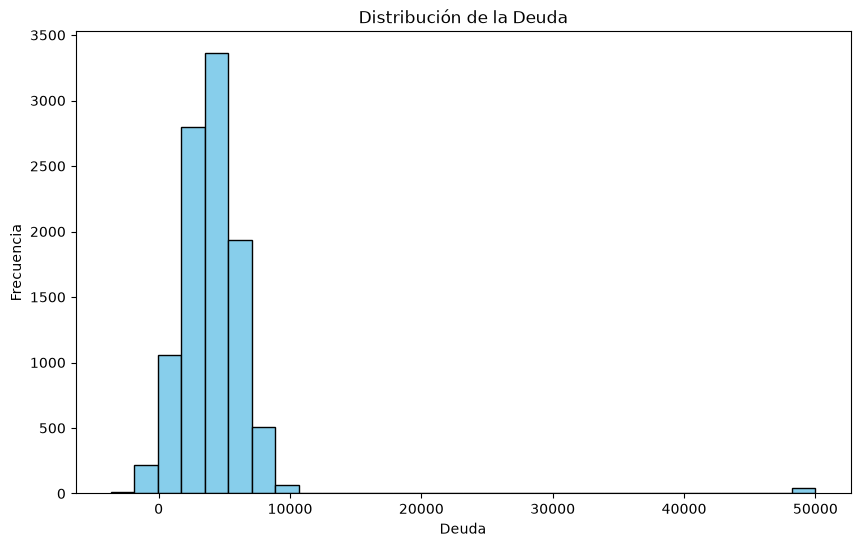

In [11]:
# Gráfica de distribución de la deuda
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['deuda'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de la Deuda')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')
plt.show()

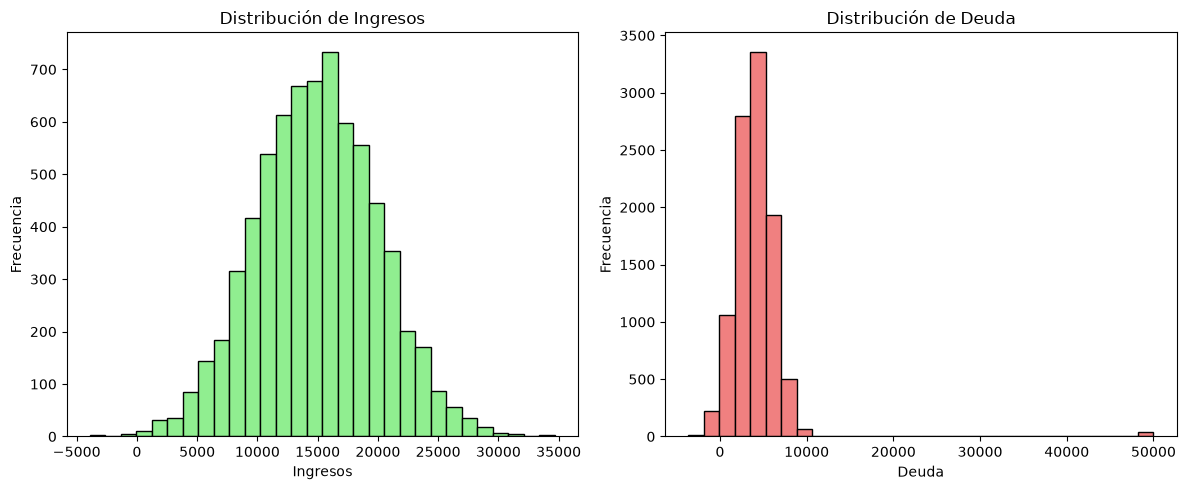

In [23]:
# Grafica de distribución de ingresos (subplot-1) y deuda (subplot-2) de tipo histograma y boxplot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df['ingresos'], bins=30, color='lightgreen', edgecolor='black')
plt.title('Distribución de Ingresos')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
plt.hist(df['deuda'], bins=30, color='lightcoral', edgecolor='black')
plt.title('Distribución de Deuda')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()